In [ ]:
import re
import unicodedata
from pathlib import Path
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks" or PROJECT_ROOT.parent.name == "notebooks":
    while PROJECT_ROOT.name != "anfibia-unsam" and PROJECT_ROOT.parent != PROJECT_ROOT:
        PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "corpus_anfibia_lematizado.csv"
STOPWORDS_PATH = PROJECT_ROOT / "data" / "processed" / "stopwords_anfibia.txt"

df = pd.read_csv(DATA_PATH, usecols=["doc_id", "category", "document_text_original", "document_text_final"])
with open(STOPWORDS_PATH, "r", encoding="utf-8") as f:
    STOPWORDS_LIST = f.read().splitlines()

def normalize_text(text):
    norm = unicodedata.normalize("NFKD", str(text))
    text = "".join(c for c in norm if not unicodedata.combining(c)).lower()
    text = re.sub(r"[^a-záéíóúüñ0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["orig_norm"] = df["document_text_original"].map(normalize_text)

vec_orig = CountVectorizer(
    lowercase=False,
    strip_accents=None,
    stop_words=STOPWORDS_LIST,
    token_pattern=r"(?u)\b[a-záéíóúüñ][a-záéíóúüñ]{2,}\b",
    min_df=3,
    max_df=0.85,
)

bow_orig = vec_orig.fit_transform(df["orig_norm"])
terms_orig = vec_orig.get_feature_names_out()

vocab_orig = pd.DataFrame({
    "term": terms_orig,
    "document_frequency": (bow_orig > 0).sum(axis=0).A1,
    "term_frequency": bow_orig.sum(axis=0).A1,
}).sort_values(["term_frequency", "document_frequency"], ascending=False)

print(f"Vocabulario sin lematizar: {len(terms_orig):,} términos")
display(vocab_orig.head(15))

Vocabulario sin lematizar: 66,675 términos


,term,document_frequency,term_frequency
51775,puede,2761,9296
31000,gobierno,1755,8274
43338,mundo,2451,8239
46114,pais,2205,7423
43212,mujeres,1445,7370
62695,trabajo,2157,7205
48063,personas,2173,6837
59172,social,2069,6805
10858,casa,1850,6767
59177,sociales,1944,5719


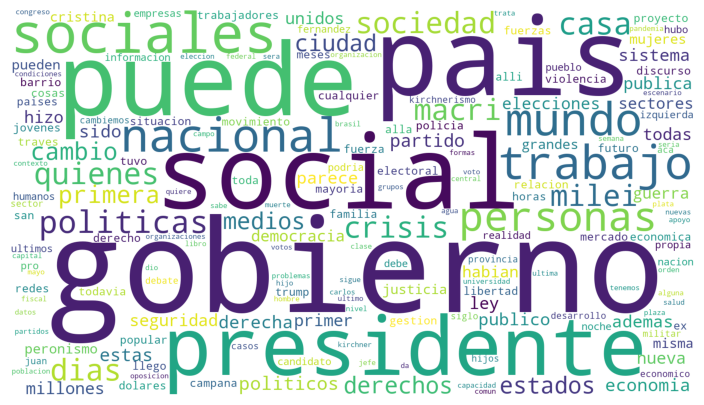

In [25]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

cat_mask = df["category"].fillna("").str.contains("Política y Economía", case=False)
texto_cat_orig = " ".join(df.loc[cat_mask, "orig_norm"])

wc_orig = WordCloud(
    width=1600,
    height=900,
    background_color="white",
    stopwords=set(STOPWORDS_LIST),
    max_words=180,
    collocations=False,
    prefer_horizontal=1.0,
    random_state=42,
    normalize_plurals=False,
).generate(texto_cat_orig)

out_path = PROJECT_ROOT / "outputs" / "figuras_informe" / "wordcloud_politica_sin_lematizar.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
wc_orig.to_file(out_path)

plt.figure(figsize=(10, 5))
plt.imshow(wc_orig)
plt.axis("off")
plt.show()

In [26]:
import coverage.types as ct
for name, fallback in {
    'Tracer': getattr(ct, 'TTracer', object),
    'TShouldTraceFn': object,
    'TShouldStartContextFn': object,
    'TFileDisposition': object,
}.items():
    if not hasattr(ct, name):
        setattr(ct, name, fallback)

import copy
import subprocess
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from bertopic import BERTopic
from bertopic.backend._utils import select_backend
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.representation import KeyBERTInspired

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.stopwords import SPANISH_STOPWORDS

# 1. Leer corpus y modelo final en modo solo lectura (sin guardar nada)
df = pd.read_parquet(ROOT / "outputs/bertopic_acotado/df_completo.parquet")
modelo_despues = BERTopic.load(str(ROOT / "outputs/bertopic_acotado/modelo_completo"))

docs = df["document_text_final"].fillna("").tolist()
topics = df["topic"].tolist()

# 2. Clonar en memoria y enganchar el backend de embeddings que no se guardó en disco
modelo_antes = copy.deepcopy(modelo_despues)
raw_emb = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
modelo_antes.embedding_model = select_backend(raw_emb)

modelo_antes.update_topics(
    docs,
    topics=topics,
    vectorizer_model=CountVectorizer(stop_words=list(SPANISH_STOPWORDS), min_df=3),
    representation_model=KeyBERTInspired(),
    top_n_words=20,
)

# 3. Comparar en consola los primeros tópicos para elegir el más claro
for t_id in range(6):
    antes_w = [w for w, _ in modelo_antes.get_topic(t_id)[:6]]
    despues_w = [w for w, _ in modelo_despues.get_topic(t_id)[:6]]
    print(f"Tópico {t_id:02d} | ANTES:   {', '.join(antes_w)}")
    print(f"Tópico {t_id:02d} | DESPUÉS: {', '.join(despues_w)}\n")

# 4. Guardar únicamente los dos gráficos de barras para el informe
TOPICO = 0  # Cambialo por el ID de arriba donde mejor se note la limpieza

for archivo, mod, color, titulo in [
    ("barras_topico_antes.png", modelo_antes, "#d62728", f"Tópico {TOPICO} — Sin stopwords"),
    ("barras_topico_despues.png", modelo_despues, "#1f77b4", f"Tópico {TOPICO} — Con stopwords"),
]:
    pares = mod.get_topic(TOPICO)[:10][::-1]
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    ax.barh([w for w, _ in pares], [s for _, s in pares], color=color)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_xlabel("Relevancia")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    out_dir = ROOT / "outputs" / "figuras_informe"
    out_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_dir / archivo, dpi=150)
    plt.close(fig)

# 5. Regenerar stopwords_anfibia.txt ejecutando src/stopwords.py
subprocess.run([sys.executable, str(ROOT / "src/stopwords.py")], cwd=str(ROOT), check=True)
print("Listo: gráficos guardados y stopwords_anfibia.txt verificado.")

2026-11-16 20:18:34,863 - BERTopic - WARNING: You are loading a BERTopic model without explicitly defining an embedding model. If you want to also load in an embedding model, make sure to use `BERTopic.load(my_model, embedding_model=my_embedding_model)`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6366.69it/s]
2026-11-16 20:18:44,574 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Tópico 00 | ANTES:   político, política, candidato, electoral, campaña, votar
Tópico 00 | DESPUÉS: candidato, electoral, campaña, debate, votar, discurso

Tópico 01 | ANTES:   autor, escritor, literatura, novela, personaje, libro
Tópico 01 | DESPUÉS: literario, autor, escritor, poeta, protagonista, literatura

Tópico 02 | ANTES:   feminismo, feminista, aborto, político, política, debate
Tópico 02 | DESPUÉS: feminismo, feminista, aborto, abortar, patriarcado, debate

Tópico 03 | ANTES:   historia, vivir, hombre, vida, muerte, contar
Tópico 03 | DESPUÉS: muerto, dictadura, muerte, morir, desaparición, cuba

Tópico 04 | ANTES:   político, política, cambio, decir, además, seguir
Tópico 04 | DESPUÉS: ambiental, ambiente, crisis, proyecto, sociedad, futuro

Tópico 05 | ANTES:   economía, crisis, pobreza, económico, reforma, inflación
Tópico 05 | DESPUÉS: déficit, economía, pobreza, económico, fiscal, deuda

Listo: gráficos guardados y stopwords_anfibia.txt verificado.


In [27]:
import pandas as pd
from bertopic import BERTopic
from pathlib import Path

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
modelo = BERTopic.load(str(ROOT / "outputs/bertopic_acotado/modelo_completo"))
df = pd.read_parquet(ROOT / "outputs/bertopic_acotado/df_completo.parquet")

# Genera el dendrograma del modelo final (22 tópicos) y lo exporta como imagen estática
fig = modelo.visualize_hierarchy(
    topics=[t for t in modelo.get_topic_info()["Topic"] if t not in (-1, 100)],
    title="Dendograma de los 22 Tópicos finales"
)
fig.write_image(str(ROOT / "outputs/figuras_informe/dendrograma_topicos_final.png"), width=1100, height=650, scale=2)

2026-11-16 20:18:57,902 - BERTopic - WARNING: You are loading a BERTopic model without explicitly defining an embedding model. If you want to also load in an embedding model, make sure to use `BERTopic.load(my_model, embedding_model=my_embedding_model)`.


In [28]:
import pandas as pd
from bertopic import BERTopic
from pathlib import Path

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
df = pd.read_parquet(ROOT / "outputs/bertopic_acotado/df_completo.parquet")
modelo = BERTopic.load(str(ROOT / "outputs/bertopic_acotado/modelo_completo"))

# Identifica automáticamente las columnas de título, bajada/tagline y probabilidad
col_titulo = [c for c in df.columns if "tit" in c.lower()][0]
cols_tagline = [c for c in df.columns if any(k in c.lower() for k in ("tag", "baj", "sub", "desc", "lead"))]
col_tagline = cols_tagline[0] if cols_tagline else None
cols_prob = [c for c in df.columns if "prob" in c.lower() or "sim" in c.lower()]

print(f"Columnas detectadas -> Título: '{col_titulo}' | Tagline: '{col_tagline}'")

for t_id in [3, 15, 4, 5]:
    print(f"\n=== TÓPICO {t_id:02d} ===")
    sub = df[df["topic"] == t_id]
    if cols_prob:
        sub = sub.sort_values(cols_prob[0], ascending=False)
    for _, row in sub.head(5).iterrows():
        print(f" - Título:  {row[col_titulo]}")
        if col_tagline:
            print(f"   Tagline: {row[col_tagline]}")

2026-11-16 20:19:01,759 - BERTopic - WARNING: You are loading a BERTopic model without explicitly defining an embedding model. If you want to also load in an embedding model, make sure to use `BERTopic.load(my_model, embedding_model=my_embedding_model)`.


Columnas detectadas -> Título: 'title_text' | Tagline: 'tagline'

=== TÓPICO 03 ===
 - Título:  Los líderes de la primavera mexicana (I)
   Tagline: nan
 - Título:  Uruguay: lapidados por la TV
   Tagline: nan
 - Título:  Jóvenes de San Judas: el México desesperado
   Tagline: nan
 - Título:  Limpiar la muerte
   Tagline: nan
 - Título:  La desahuciada que narra
   Tagline: nan

=== TÓPICO 15 ===
 - Título:  Cacerolas: rebelión y felicidad
   Tagline: nan
 - Título:  Tortas, putos y cumbieros
   Tagline: nan
 - Título:  Sentirse boliviano en Buenos Aires
   Tagline: nan
 - Título:  Alasitas: mito, tradición y modernidad
   Tagline: La fiesta-feria del Ekeko
 - Título:  La revolución de la policía
   Tagline: nan

=== TÓPICO 04 ===
 - Título:  La China invisible
   Tagline: Feria La Salada
 - Título:  Los arruinados del Paraná
   Tagline: Adictos al juego
 - Título:  La reforma agraria de las mujeres guaraníes
   Tagline: nan
 - Título:  Epecuén jamás se inundaría
   Tagline: Adelanto
 

In [29]:
import math
from pathlib import Path
from bertopic import BERTopic
import pandas as pd
import plotly.express as px

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
FIGURAS_DIR = ROOT / "outputs" / "figuras_informe"
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

# Cargamos el modelo definitivo (con tópicos reordenados y Tópico 100)
df_acotado = pd.read_parquet(
    ROOT / "outputs/bertopic_acotado/df_modelo_acotado.parquet"
)
df_comp = pd.read_parquet(ROOT / "outputs/bertopic_acotado/df_completo.parquet")
modelo = BERTopic.load(str(ROOT / "outputs/bertopic_acotado/modelo_completo"))

# Reconstruimos el mapeo de conteos base (antes del umbral) alineado al orden final (0..21 y 100)
conteo_antes_raw = df_acotado["topic_cuarta"].value_counts()
conteo_despues_raw = df_acotado["topic_umbral"].value_counts()
ranking_tematicos = (
    conteo_despues_raw[conteo_despues_raw.index != -1].index.tolist()
)
mapeo_reorden = {
    viejo: nuevo for nuevo, viejo in enumerate(ranking_tematicos)
}
mapeo_reorden[-1] = 100

conteo_antes_final = {}
for viejo_id, n in conteo_antes_raw.items():
  conteo_antes_final[mapeo_reorden[viejo_id]] = n

conteo_despues_final = df_comp["topic"].value_counts()

print(
    "| Tópico | Palabras clave principales | Artículos (base) | Artículos"
    " (umbral ≥ 0,65) | Variación |"
)
print("| :--- | :--- | :---: | :---: | :---: |")

for t in list(range(22)) + [100]:
  kws = ", ".join([w for w, _ in modelo.get_topic(t)[:6]])
  n_antes = conteo_antes_final.get(t, 0)
  n_despues = conteo_despues_final.get(t, 0)
  diff = n_despues - n_antes
  diff_str = f"+{diff}" if diff >= 0 else str(diff)
  print(f"| **{t:02d}** | *{kws}* | {n_antes} | {n_despues} | {diff_str} |")

2026-11-16 20:19:02,303 - BERTopic - WARNING: You are loading a BERTopic model without explicitly defining an embedding model. If you want to also load in an embedding model, make sure to use `BERTopic.load(my_model, embedding_model=my_embedding_model)`.


| Tópico | Palabras clave principales | Artículos (base) | Artículos (umbral ≥ 0,65) | Variación |
| :--- | :--- | :---: | :---: | :---: |
| **00** | *candidato, electoral, campaña, debate, votar, discurso* | 456 | 620 | +164 |
| **01** | *literario, autor, escritor, poeta, protagonista, literatura* | 304 | 392 | +88 |
| **02** | *feminismo, feminista, aborto, abortar, patriarcado, debate* | 288 | 334 | +46 |
| **03** | *muerto, dictadura, muerte, morir, desaparición, cuba* | 164 | 247 | +83 |
| **04** | *ambiental, ambiente, crisis, proyecto, sociedad, futuro* | 144 | 198 | +54 |
| **05** | *déficit, economía, pobreza, económico, fiscal, deuda* | 139 | 195 | +56 |
| **06** | *futbolista, fifa, fútbol, brasil, barcelona, deporte* | 129 | 141 | +12 |
| **07** | *pedagógico, enseñanza, escolar, educativo, enseñar, educación* | 115 | 126 | +11 |
| **08** | *epidemia, pandemia, vacunar, virus, vacuna, vacunación* | 98 | 126 | +28 |
| **09** | *periodístico, mediático, periodista, noticia, 

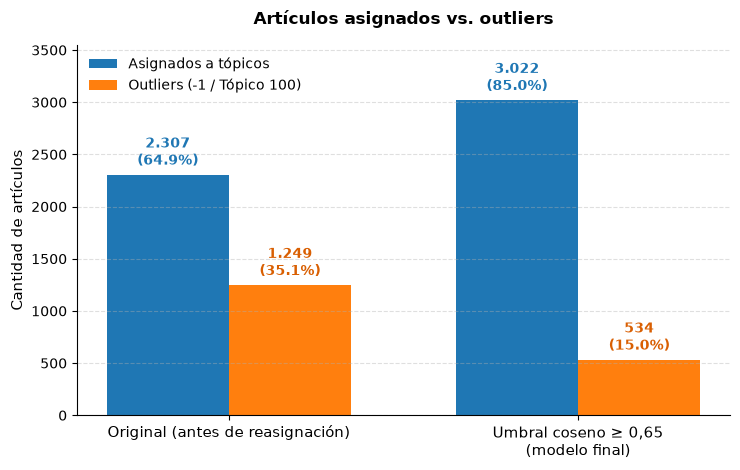

Gráfico guardado en: C:\Trabajos\anfibia-unsam\outputs\figuras_informe\proporcion_outliers.png


In [30]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
FIGURAS_DIR = ROOT / "outputs" / "figuras_informe"
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

etapas = ["Original (antes de reasignación)", "Umbral coseno ≥ 0,65\n(modelo final)"]
asignados = [2307, 3022]
outliers = [1249, 534]
total = 3556

x = np.arange(len(etapas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(7.5, 4.8))

barras_asig = ax.bar(x - ancho/2, asignados, ancho, label="Asignados a tópicos", color="#1f77b4")
barras_out = ax.bar(x + ancho/2, outliers, ancho, label="Outliers (-1 / Tópico 100)", color="#ff7f0e")

# Etiquetas con cantidad y porcentaje dentro/encima de cada barra
for barra in barras_asig:
    h = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width()/2, h + 50,
        f"{h:,}\n({h/total:.1%})".replace(",", "."),
        ha="center", va="bottom", fontweight="bold", fontsize=10, color="#1f77b4"
    )

for barra in barras_out:
    h = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width()/2, h + 50,
        f"{h:,}\n({h/total:.1%})".replace(",", "."),
        ha="center", va="bottom", fontweight="bold", fontsize=10, color="#d95f02"
    )

ax.set_ylabel("Cantidad de artículos", fontsize=11)
ax.set_title("Artículos asignados vs. outliers", fontsize=12, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(etapas, fontsize=10.5)
ax.set_ylim(0, 3550)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=10, loc="upper left")

plt.tight_layout()
ruta_salida = FIGURAS_DIR / "proporcion_outliers.png"
plt.savefig(ruta_salida, dpi=300)
plt.show()
print("Gráfico guardado en:", ruta_salida)

In [42]:
from pathlib import Path
from bertopic import BERTopic
import pandas as pd
import plotly.graph_objects as go

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
FIGURAS_DIR = ROOT / "outputs" / "figuras_informe"
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(ROOT / "outputs/bertopic_acotado/df_completo.parquet")
modelo = BERTopic.load(str(ROOT / "outputs/bertopic_acotado/modelo_completo"))

df["post_date_dt"] = pd.to_datetime(
    df["post_date"].str.split(" ").str[0], format="%Y-%m-%d", errors="coerce"
)
mask = df["post_date_dt"].notna() & df[
    "document_text_final"
].fillna("").str.strip().ne("")

# Calculamos las 40 ventanas temporales igual que en el análisis
tot = modelo.topics_over_time(
    docs=df.loc[mask, "document_text_final"].tolist(),
    topics=df.loc[mask, "topic"].astype(int).tolist(),
    timestamps=df.loc[mask, "post_date_dt"].dt.to_pydatetime().tolist(),
    nr_bins=40,
)

topicos_mostrar = {
    2: ("02: " + "_".join([w for w, _ in modelo.get_topic(2)[:3]]), "#d62728"),
    8: ("08: " + "_".join([w for w, _ in modelo.get_topic(8)[:3]]), "#2ca02c"),
}

fig_tot = go.Figure()

for t_id, (etiqueta, color) in topicos_mostrar.items():
  sub = tot[tot["Topic"] == t_id].sort_values("Timestamp")
  fig_tot.add_trace(
      go.Scatter(
          x=sub["Timestamp"],
          y=sub["Frequency"],
          mode="lines+markers",
          name=etiqueta,
          line=dict(color=color, width=2.8),
          marker=dict(size=6),
      )
  )

  # Detectar automáticamente el pico máximo de la ventana para anclar la anotación
  pico = sub.sort_values("Frequency", ascending=False).iloc[0]
  texto_pico = (
      "Debate IVE" if t_id == 2 else "Inicio pandemia"
  )
  ax_offset = -65 if t_id == 2 else 75

  fig_tot.add_annotation(
      x=pico["Timestamp"],
      y=pico["Frequency"],
      text=f"<b>{texto_pico}</b>",
      showarrow=True,
      arrowhead=2,
      arrowsize=1,
      arrowwidth=1.5,
      arrowcolor=color,
      ax=ax_offset,
      ay=-18,
      font=dict(size=11, color=color),
      bgcolor="rgba(255,255,255,0.9)",
      bordercolor=color,
      borderwidth=1,
      borderpad=4,
  )

max_y = tot[tot["Topic"].isin([2, 8])]["Frequency"].max()

fig_tot.update_layout(
    title=(
        "<b>Evolución temporal: Tópico 02 vs. Tópico 08"
    ),
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="#ffffff",
    xaxis=dict(
        title="Fecha de publicación",
        gridcolor="#eeeeee",
    ),
    yaxis=dict(
        title="Artículos Publicados",
        gridcolor="#eeeeee",
        rangemode="tozero",
        range=[0, max_y * 1.15],
    ),
    legend=dict(
        title="<b>Tópico</b>",
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
    ),
    margin=dict(t=85, b=50, l=55, r=30),
)

fig_tot.write_image(
    str(FIGURAS_DIR / "evolucion_temporal_topicos.png"),
    width=1150,
    height=540,
    scale=2,
)
fig_tot.show()

2026-11-16 20:48:07,912 - BERTopic - WARNING: You are loading a BERTopic model without explicitly defining an embedding model. If you want to also load in an embedding model, make sure to use `BERTopic.load(my_model, embedding_model=my_embedding_model)`.


In [45]:
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
df = pd.read_parquet(
    ROOT / "outputs/bertopic_acotado/df_completo.parquet",
    columns=["title_text", "tagline"],
)

filas = [
    ("00", "Política electoral", "2017-08", 29, "Los peligros de la posmilitancia"),
    ("02", "Feminismos", "2018-05", 43, "Aborto es lengua popular"),
    ("05", "Economía", "2023-04", 14, "Corrupción, un asunto de derechos"),
    ("08", "Salud y pandemia", "2020-02", 41, "Sabía que ibas a reaccionar así"),
]

print("| Tópico | Pico máximo (fecha) | Frecuencia | Artículo representativo | Tagline |")
print("| :--- | :---: | :---: | :--- | :--- |")

for tid, desc, fecha, freq, titulo in filas:
  match = df[df["title_text"].str.strip().str.lower() == titulo.lower()]
  tag = match["tagline"].iloc[0] if not match.empty and pd.notna(match["tagline"].iloc[0]) else "—"
  tag = str(tag).strip() or "—"
  print(f"| **{tid}** *({desc})* | {fecha} | {freq} | *{titulo}* | {tag} |")

| Tópico | Pico máximo (fecha) | Frecuencia | Artículo representativo | Tagline |
| :--- | :---: | :---: | :--- | :--- |
| **00** *(Política electoral)* | 2017-08 | 29 | *Los peligros de la posmilitancia* | El escenario después de la reforma previsional |
| **02** *(Feminismos)* | 2018-05 | 43 | *Aborto es lengua popular* | Después del 8A |
| **05** *(Economía)* | 2023-04 | 14 | *Corrupción, un asunto de derechos* | Revertir la captura del estado para fortalecer la democracia |
| **08** *(Salud y pandemia)* | 2020-02 | 41 | *Sabía que ibas a reaccionar así* | Cómo nos comportamos ante la flexibilización |


In [46]:
import ast
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
df = pd.read_parquet(
    ROOT / "outputs/bertopic_acotado/df_completo.parquet",
    columns=["doc_id", "topic", "autor_names"],
)


def parse_autores(val):
  if pd.isna(val):
    return []
  if isinstance(val, (list, tuple)):
    return [str(x).strip() for x in val if str(x).strip()]
  s = str(val).strip()
  if s.startswith("[") and s.endswith("]"):
    try:
      return [str(x).strip() for x in ast.literal_eval(s) if str(x).strip()]
    except Exception:
      pass
  return [x.strip() for x in s.split(",") if x.strip()]


df["autores_lista"] = df["autor_names"].apply(parse_autores)
df_exp = df.explode("autores_lista").dropna(subset=["autores_lista"])

totales_autor = df_exp.groupby("autores_lista")["doc_id"].nunique()

topicos_obj = {
    0: "Política electoral",
    1: "Literatura",
    2: "Feminismos",
    5: "Economía",
    6: "Fútbol",
}

print(
    "| Tópico | Autor destacado | Notas en el tópico | Total de notas del"
    " autor | Especialización en el tópico |"
)
print("| :--- | :--- | :---: | :---: | :---: |")

for tid, desc in topicos_obj.items():
  conteo_t = (
      df_exp[df_exp["topic"] == tid]
      .groupby("autores_lista")["doc_id"]
      .nunique()
      .sort_values(ascending=False)
  )
  autor = conteo_t.index[0]
  n_topico = int(conteo_t.iloc[0])
  n_total = int(totales_autor[autor])
  pct = f"{(n_topico / n_total) * 100:.1f} %".replace(".", ",")
  print(
      f"| **{tid:02d}** *({desc})* | {autor} | {n_topico} | {n_total} |"
      f" {pct} |"
  )

| Tópico | Autor destacado | Notas en el tópico | Total de notas del autor | Especialización en el tópico |
| :--- | :--- | :---: | :---: | :---: |
| **00** *(Política electoral)* | Esteban De Gori | 22 | 27 | 81,5 % |
| **01** *(Literatura)* | Julieta Greco | 12 | 23 | 52,2 % |
| **02** *(Feminismos)* | Luciana Peker | 10 | 13 | 76,9 % |
| **05** *(Economía)* | Juan Pablo Bohoslavsky | 8 | 9 | 88,9 % |
| **06** *(Fútbol)* | Alejandro Wall | 11 | 16 | 68,8 % |


In [47]:
import difflib
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import spacy

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
FIGURAS_DIR = ROOT / "outputs" / "figuras_informe"
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)
ETIQUETAS_DIR = ROOT / "outputs" / "analisis_etiquetas"

df = pd.read_parquet(ROOT / "outputs/bertopic_acotado/df_completo.parquet")
df["post_year"] = pd.to_datetime(
    df["post_date"].astype(str).str.split(" ").str[0], errors="coerce"
).dt.year
df["tiene_tag"] = df["post_tag"].notna() & (df["post_tag"].str.strip() != "")

# 1. Métricas de cobertura y fragmentación
total = len(df)
con_tag = int(df["tiene_tag"].sum())
sin_tag = total - con_tag

tags_list = (
    df["post_tag"]
    .dropna()
    .str.split(r";")
    .explode()
    .str.strip()
    .loc[lambda x: x != ""]
)
tag_counts = tags_list.value_counts()
tags_unicos = len(tag_counts)
tags_una_vez = int((tag_counts == 1).sum())

print("=== 1. NÚMEROS GENERALES ===")
print(f"Total notas: {total:,}")
print(f"Con etiqueta: {con_tag:,} ({con_tag/total*100:.1f}%)")
print(f"Sin etiqueta: {sin_tag:,} ({sin_tag/total*100:.1f}%)")
print(f"Etiquetas únicas: {tags_unicos:,}")
print(
    f"Etiquetas usadas 1 sola vez: {tags_una_vez:,}"
    f" ({tags_una_vez/tags_unicos*100:.1f}%)"
)
print("\nTop 10 etiquetas más usadas:")
for tag, freq in tag_counts.head(10).items():
  print(f" - {tag}: {freq}")

# 2. Leer los CSV ya generados por el notebook 06 para no recalcular nada
print("\n=== 2. REPORTES YA GENERADOS EN outputs/analisis_etiquetas/ ===")
for nombre_csv in [
    "tags_solapamiento_documentos.csv",
    "tags_solapamiento_prob_topicos.csv",
    "tags_cuasiduplicados_lexicos.csv",
    "tags_fusiones_automaticas.csv",
    "tags_revision_manual.csv",
]:
  ruta = ETIQUETAS_DIR / nombre_csv
  if ruta.exists():
    d_tmp = pd.read_csv(ruta)
    print(f"\nArchivo: {nombre_csv} -> {len(d_tmp):,} filas")
    print(d_tmp.head(5).to_string(index=False))

# 3. Gráfico A: Evolución de artículos etiquetados por año (.png)
evolucion = (
    df.groupby("post_year")
    .agg(total_notas=("doc_id", "count"), notas_con_tag=("tiene_tag", "sum"))
    .reset_index()
)
evolucion["notas_sin_tag"] = (
    evolucion["total_notas"] - evolucion["notas_con_tag"]
)
evolucion["pct_con_tag"] = (
    evolucion["notas_con_tag"] / evolucion["total_notas"] * 100
).round(1)
textos_verdes = [f"{p:.0f}%" if p > 8 else "" for p in evolucion["pct_con_tag"]]

fig_evo = go.Figure()
fig_evo.add_trace(
    go.Bar(
        x=evolucion["post_year"],
        y=evolucion["notas_con_tag"],
        name="Con Etiquetas",
        marker_color="#2ca02c",
        text=textos_verdes,
        textposition="inside",
        textangle=0,
        insidetextanchor="middle",
    )
)
fig_evo.add_trace(
    go.Bar(
        x=evolucion["post_year"],
        y=evolucion["notas_sin_tag"],
        name="Sin Etiquetas",
        marker_color="#d62728",
    )
)
fig_evo.update_layout(
    barmode="stack",
    title="<b>Artículos con y sin etiquetas por año (2012–2026)</b>",
    xaxis_title="Año de publicación",
    yaxis_title="Cantidad de artículos",
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="#ffffff",
    legend=dict(
        orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1
    ),
    margin=dict(t=75, b=50, l=55, r=30),
)
fig_evo.update_xaxes(type="category")
fig_evo.write_image(
    str(FIGURAS_DIR / "evolucion_etiquetado_anual.png"),
    width=1100,
    height=480,
    scale=2,
)

# 4. Gráfico B: Ranking de fragmentación por tópico (.png)
solap = pd.read_csv(ETIQUETAS_DIR / "auditoria_tags_por_topico.csv")
df_ranking = (
    solap[solap["notas_con_tag"] >= 15]
    .assign(
        ratio_fragmentacion=lambda d: (
            d["tags_unicos_usados"] / d["notas_con_tag"]
        ).round(2)
    )
    .nlargest(12, "ratio_fragmentacion")
    .iloc[::-1]
)
fig_rank = px.bar(
    df_ranking,
    x="ratio_fragmentacion",
    y="topic_name",
    orientation="h",
    color="ratio_fragmentacion",
    color_continuous_scale="Reds",
    text="ratio_fragmentacion",
    title=(
        "<b>Tópicos con mayor dispersión de etiquetas (Ratio de"
        " Fragmentación)</b>"
    ),
    labels={
        "ratio_fragmentacion": "Ratio (Tags únicos / Notas con tag)",
        "topic_name": "",
    },
)
fig_rank.update_traces(textposition="outside", texttemplate="%{text:.2f}")
fig_rank.update_layout(
    xaxis_range=[0, df_ranking["ratio_fragmentacion"].max() * 1.15],
    coloraxis_showscale=False,
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="#ffffff",
    margin=dict(t=70, b=45, l=220, r=45),
)
fig_rank.write_image(
    str(FIGURAS_DIR / "ranking_fragmentacion_etiquetas.png"),
    width=1100,
    height=500,
    scale=2,
)
print("\nGráficos guardados en outputs/figuras_informe/.")

=== 1. NÚMEROS GENERALES ===
Total notas: 3,556
Con etiqueta: 1,589 (44.7%)
Sin etiqueta: 1,967 (55.3%)
Etiquetas únicas: 881
Etiquetas usadas 1 sola vez: 444 (50.4%)

Top 10 etiquetas más usadas:
 - Internacional: 238
 - Javier Milei: 162
 - Derechas: 114
 - Zapping cultural: 84
 - Derechos Humanos: 77
 - UNSAM: 67
 - Chile: 65
 - Feminismos: 62
 - Peronismo: 61
 - Libros: 59

=== 2. REPORTES YA GENERADOS EN outputs/analisis_etiquetas/ ===

Archivo: tags_solapamiento_documentos.csv -> 107 filas
         Tag A                       Tag B  Notas_Compartidas  Indice_Solapamiento_Jaccard
  Adolescencia Salud Sexual Y Reproductiva                  3                          1.0
  Adolescencia         Maternidad Temprana                  3                          1.0
  Adolescencia              Anticoncepción                  3                          1.0
Anticoncepción         Maternidad Temprana                  3                          1.0
Anticoncepción Salud Sexual Y Reproductiva  

In [48]:
from pathlib import Path
import pandas as pd
import plotly.express as px

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
FIGURAS_DIR = ROOT / "outputs" / "figuras_informe"
ETIQUETAS_DIR = ROOT / "outputs" / "analisis_etiquetas"

solap = pd.read_csv(ETIQUETAS_DIR / "auditoria_tags_por_topico.csv")

df_ranking = solap.assign(
    ratio_fragmentacion=lambda d: (
        d["tags_unicos_usados"] / d["notas_con_tag"]
    ).round(2)
).sort_values("ratio_fragmentacion", ascending=True)

fig_rank = px.bar(
    df_ranking,
    x="ratio_fragmentacion",
    y="topic_name",
    orientation="h",
    color="ratio_fragmentacion",
    color_continuous_scale="Reds",
    text="ratio_fragmentacion",
    title=(
        "<b>Dispersión de etiquetas por tópico (Ratio de Fragmentación)</b>"
    ),
    labels={
        "ratio_fragmentacion": "Ratio (Tags únicos / Notas con tag)",
        "topic_name": "",
    },
)

fig_rank.update_traces(textposition="outside", texttemplate="%{text:.2f}")
fig_rank.update_layout(
    xaxis_range=[0, df_ranking["ratio_fragmentacion"].max() * 1.15],
    coloraxis_showscale=False,
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="#ffffff",
    height=780,
    margin=dict(t=65, b=45, l=230, r=45),
)

fig_rank.write_image(
    str(FIGURAS_DIR / "ranking_fragmentacion_etiquetas.png"),
    width=1100,
    height=780,
    scale=2,
)
fig_rank.show()

## 2.5

In [58]:
from pathlib import Path
from bertopic import BERTopic
from bertopic.backend._utils import select_backend
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from umap import UMAP

ROOT = Path(r"C:\Trabajos\anfibia-unsam")
INPUT_DIR = ROOT / "outputs" / "bertopic_acotado"
FIGURAS_DIR = ROOT / "outputs" / "figuras_informe"
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(INPUT_DIR / "df_completo.parquet")
if "doc_id" not in df.columns:
  df["doc_id"] = df.index

topic_model = BERTopic.load(str(INPUT_DIR / "modelo_completo"))
raw_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
topic_model.embedding_model = select_backend(raw_model)

# 1. Calcular distribuciones suaves de tópicos (N x 23)
textos_docs = df["document_text_final"].fillna("").astype(str).tolist()
doc_topic_dist, _ = topic_model.approximate_distribution(
    textos_docs, use_embedding_model=False
)

all_topics = sorted(df["topic"].unique())
topic_words_dict = {
    t_id: (
        "100_outliers_miscelaneo"
        if t_id == 100
        else f"{t_id}_" + "_".join([w for w, _ in topic_model.get_topic(t_id)[:3]])
    )
    for t_id in all_topics
}
df["topic"] = df["topic"].map(topic_words_dict)

# 2. Caso de prueba (podés cambiar 150 por otro doc_id si querés)
TARGET_ID = 150
sims = cosine_similarity(
    doc_topic_dist[TARGET_ID].reshape(1, -1), doc_topic_dist
).flatten()
top_idx = [i for i in sims.argsort()[::-1] if i != TARGET_ID][:10]

orig = df.iloc[TARGET_ID]
print("=== ARTÍCULO CONSULTADO ===")
print(f"doc_id: {TARGET_ID} | Título: {orig['title_text']}")
print(f"Tópico dominante: {orig['topic']} | Tags: {orig['post_tag']}")

print("\n=== TABLA TOP 5 RECOMENDADOS (MARKDOWN) ===")
print("| Rank | Título | Tópico dominante | Etiquetas (`post_tag`) | Similitud |")
print("| :---: | :--- | :--- | :--- | :---: |")
for r, idx in enumerate(top_idx[:5], start=1):
  row = df.iloc[idx]
  tags = (
      str(row["post_tag"]).strip()
      if pd.notna(row["post_tag"]) and str(row["post_tag"]).strip()
      else "Sin etiquetas"
  )
  print(
      f"| {r} | *{row['title_text'].strip()}* | `{row['topic']}` | {tags}"
      f" | {sims[idx]:.4f} |"
  )

# 3. Gráfico A: Espacio Temático UMAP 2D con recomendaciones
reducer_tem = UMAP(n_neighbors=15, n_components=2, metric="cosine", random_state=42)
coords_tem = reducer_tem.fit_transform(doc_topic_dist)
df["umap_tem_x"] = coords_tem[:, 0]
df["umap_tem_y"] = coords_tem[:, 1]

df_resto = df[~df["doc_id"].isin([TARGET_ID] + top_idx)]
df_rec = df[df["doc_id"].isin(top_idx)].copy()
df_target = df[df["doc_id"] == TARGET_ID]

fig_map = px.scatter(
    df_resto,
    x="umap_tem_x",
    y="umap_tem_y",
    color="topic",
    color_discrete_sequence=px.colors.qualitative.Alphabet,
)
fig_map.update_traces(marker=dict(size=5, opacity=0.45))
fig_map.add_trace(
    go.Scatter(
        x=df_rec["umap_tem_x"],
        y=df_rec["umap_tem_y"],
        mode="markers",
        name="Top 10 Recomendados",
        marker=dict(
            symbol="circle",
            size=14,
            color="#FFD700",
            line=dict(width=2, color="#111111"),
        ),
    )
)
fig_map.add_trace(
    go.Scatter(
        x=df_target["umap_tem_x"],
        y=df_target["umap_tem_y"],
        mode="markers",
        name="Artículo Consultado",
        marker=dict(
            symbol="diamond",
            size=18,
            color="#d62728",
            line=dict(width=2, color="#111111"),
        ),
    )
)
fig_map.update_layout(
    title=(
        "<b>Ubicación en el espacio temático (UMAP sobre probabilidades de"
        " tópicos)</b>"
    ),
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="#ffffff",
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False, title=""),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, title=""),
    legend=dict(title="<b>Referencias y Tópicos</b>", font=dict(size=10)),
    margin=dict(t=60, b=20, l=20, r=20),
)
fig_map.write_image(
    str(FIGURAS_DIR / "recomendador_mapa_tematico.png"),
    width=1200,
    height=680,
    scale=2,
)

# 4. Gráfico B: Composición temática del artículo original vs Top 5
ids_comp = [TARGET_ID] + top_idx[:5]
nombres_y = [
    f"[ORIGINAL] {df.iloc[TARGET_ID]['title_text'][:36]}..."
] + [f"[#{i+1}] {df.iloc[idx]['title_text'][:36]}..." for i, idx in enumerate(top_idx[:5])]
vectores = doc_topic_dist[ids_comp]
top_cols = np.argsort(vectores.sum(axis=0))[::-1][:6]

datos_bar = []
for i, vec in enumerate(vectores):
  otros = 0.0
  for col_idx, peso in enumerate(vec):
    if col_idx in top_cols and peso >= 0.02:
      t_real = all_topics[col_idx]
      datos_bar.append({
          "Artículo": nombres_y[i],
          "Tópico": topic_words_dict[t_real],
          "Proporción": peso,
      })
    else:
      otros += peso
  if otros > 0:
    datos_bar.append({
        "Artículo": nombres_y[i],
        "Tópico": "Otros tópicos menores",
        "Proporción": otros,
    })

fig_bar = px.bar(
    pd.DataFrame(datos_bar),
    x="Proporción",
    y="Artículo",
    color="Tópico",
    orientation="h",
    title=(
        "<b>Composición temática: artículo consultado vs. Top 5"
        " recomendaciones</b>"
    ),
    color_discrete_sequence=px.colors.qualitative.G10,
)
fig_bar.update_layout(
    template="plotly_white",
    xaxis_tickformat=".0%",
    yaxis={"categoryorder": "array", "categoryarray": nombres_y[::-1]},
    legend=dict(
        orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1
    ),
    margin=dict(t=85, b=40, l=240, r=30),
)
fig_bar.write_image(
    str(FIGURAS_DIR / "recomendador_composicion_topicos.png"),
    width=1150,
    height=480,
    scale=2,
)
print("\nGráficos guardados en outputs/figuras_informe/.")

2026-11-17 00:00:17,749 - BERTopic - WARNING: You are loading a BERTopic model without explicitly defining an embedding model. If you want to also load in an embedding model, make sure to use `BERTopic.load(my_model, embedding_model=my_embedding_model)`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3096.70it/s]


KeyboardInterrupt: 

In [50]:
import pandas as pd

df = pd.read_parquet(
    r"C:\Trabajos\anfibia-unsam\outputs\bertopic_acotado\df_completo.parquet"
)
titulos = [
    "Cruzamos el Rubicón",
    "Acá estoy yo, para salvarlos",
    "La dificultad de ser mejor que los otros",
]
print(df[df["title_text"].isin(titulos)][["title_text", "tagline"]].to_string(index=False))

                              title_text                    tagline
                     Cruzamos el Rubicón       Argentina vs Bélgica
La dificultad de ser mejor que los otros Anfibia en la Copa América
            Acá estoy yo, para salvarlos         Messi, el redentor


In [51]:
sims = cosine_similarity(
    doc_topic_dist[TARGET_ID].reshape(1, -1), doc_topic_dist
).flatten()
rec1_id = [i for i in sims.argsort()[::-1] if i != TARGET_ID][0]

titulo_origen = df.loc[df["doc_id"] == TARGET_ID, "title_text"].iloc[0]
titulo_rec1 = df.loc[df["doc_id"] == rec1_id, "title_text"].iloc[0]

vec_origen = doc_topic_dist[TARGET_ID]
vec_rec1 = doc_topic_dist[rec1_id]

nombres_x, valores_origen, valores_rec1, diferencias, alturas_max = (
    [],
    [],
    [],
    [],
    [],
)

for col_idx, t_id in enumerate(all_topics):
  nombre = topic_words_dict[t_id]
  nombres_x.append(nombre[:26] + "..." if len(nombre) > 28 else nombre)

  v_orig, v_rec = vec_origen[col_idx], vec_rec1[col_idx]
  valores_origen.append(v_orig)
  valores_rec1.append(v_rec)
  alturas_max.append(max(v_orig, v_rec))

  diff = v_rec - v_orig
  diferencias.append(
      f"<b>{'+' if diff > 0 else ''}{diff*100:.1f}%</b>"
      if abs(diff) >= 0.005
      else ""
  )

ymax = max(max(valores_origen), max(valores_rec1))

fig = go.Figure()
fig.add_trace(
    go.Bar(
        x=nombres_x,
        y=valores_origen,
        name=f"Original: {titulo_origen}",
        marker_color="rgba(214, 39, 40, 0.65)",
        marker_line_color="rgba(214, 39, 40, 1)",
        marker_line_width=1.5,
    )
)
fig.add_trace(
    go.Bar(
        x=nombres_x,
        y=valores_rec1,
        name=f"Recomendación #1: {titulo_rec1}",
        marker_color="rgba(31, 119, 180, 0.65)",
        marker_line_color="rgba(31, 119, 180, 1)",
        marker_line_width=1.5,
    )
)
fig.add_trace(
    go.Bar(
        x=nombres_x,
        y=alturas_max,
        text=diferencias,
        textposition="outside",
        textfont=dict(size=10, color="#222222"),
        marker_color="rgba(0,0,0,0)",
        marker_line_color="rgba(0,0,0,0)",
        showlegend=False,
    )
)

fig.update_layout(
    title=(
        "<b>Comparación de distribución de tópicos: Original vs."
        " Recomendación #1</b>"
    ),
    barmode="overlay",
    template="plotly_white",
    margin=dict(t=85, b=130, l=60, r=30),
    yaxis=dict(
        tickformat=".0%", title="Peso del tópico", range=[0, ymax * 1.18]
    ),
    xaxis=dict(
        tickangle=-35, categoryorder="array", categoryarray=nombres_x
    ),
    legend=dict(
        orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1
    ),
)

fig.write_image(
    str(FIGURAS_DIR / "recomendador_composicion_topicos.png"),
    width=1200,
    height=550,
    scale=2,
)
fig.show()

In [53]:
top2 = np.sort(doc_topic_dist, axis=1)[:, -2:]
mask_hibridos = (
    (top2[:, 1] >= 0.45) & (top2[:, 1] <= 0.65) & (top2[:, 0] >= 0.20)
)
candidatos = df[mask_hibridos][["doc_id", "title_text", "topic"]].head(15)
print(candidatos.to_string(index=False))

 doc_id                                                        title_text  topic
    138                                            La caída del Mosquetón      3
    173                               Una mujer puerca y un Dios personal      1
    331                            Pedro nuestro que estás en los espejos      1
    376 J. M. Coetzee dirigirá la Cátedra Literaturas del Sur de la UNSAM      1
    413                                                     Ultraviolento    100
    432                                               Susurros en el agua     21
    444                                                A pescar tiburones      3
   1003                                      Contra las reglas del género    100
   1029                               El comentario desubicado en el aula      2
   1040                            La Carta de Walsh: fuentes consultadas      1
   1064                                              Ni machos, ni fachos      2
   1176                     

In [61]:
df["topic_label"] = df["topic"].map(topic_words_dict)

In [63]:
from umap import UMAP

# Compute UMAP coordinates only if they aren't in df yet
if "umap_tem_x" not in df.columns:
  reducer_tem = UMAP(
      n_neighbors=15, n_components=2, metric="cosine", random_state=42
  )
  coords_tem = reducer_tem.fit_transform(doc_topic_dist)
  df["umap_tem_x"] = coords_tem[:, 0]
  df["umap_tem_y"] = coords_tem[:, 1]

TARGET_ID = 1029

sims = cosine_similarity(
    doc_topic_dist[TARGET_ID].reshape(1, -1), doc_topic_dist
).flatten()
top10_ids = [i for i in sims.argsort()[::-1] if i != TARGET_ID][:10]

orig = df.iloc[TARGET_ID]
print(f"=== ARTÍCULO CONSULTADO (doc_id: {TARGET_ID}) ===")
print(
    f"Título: {orig['title_text']} | Tópico: {orig['topic']} | Tags:"
    f" {orig['post_tag']}\n"
)

print("| Rank | Título | Tópico dominante | Etiquetas (`post_tag`) | Similitud |")
print("| :---: | :--- | :--- | :--- | :---: |")
for r, idx in enumerate(top10_ids[:5], start=1):
  row = df.iloc[idx]
  tags = (
      str(row["post_tag"]).strip()
      if pd.notna(row["post_tag"]) and str(row["post_tag"]).strip()
      else "Sin etiquetas"
  )
  print(
      f"| {r} | *{row['title_text'].strip()}* | `{row['topic_label']}` | {tags}"
      f" | {sims[idx]:.4f} |"
  )

# 1. Mapa UMAP
df_resto = df[~df["doc_id"].isin([TARGET_ID] + top10_ids)]
df_rec = df[df["doc_id"].isin(top10_ids)]
df_target = df[df["doc_id"] == TARGET_ID]

fig_map = px.scatter(
    df_resto,
    x="umap_tem_x",
    y="umap_tem_y",
    color="topic_label",
    color_discrete_sequence=px.colors.qualitative.Alphabet,
)
fig_map.update_traces(marker=dict(size=5, opacity=0.45))
fig_map.add_trace(
    go.Scatter(
        x=df_rec["umap_tem_x"],
        y=df_rec["umap_tem_y"],
        mode="markers",
        name="Top 10 Recomendados",
        marker=dict(
            symbol="circle",
            size=14,
            color="#FFD700",
            line=dict(width=2, color="#111111"),
        ),
    )
)
fig_map.add_trace(
    go.Scatter(
        x=df_target["umap_tem_x"],
        y=df_target["umap_tem_y"],
        mode="markers",
        name="Artículo Consultado",
        marker=dict(
            symbol="diamond",
            size=18,
            color="#d62728",
            line=dict(width=2, color="#111111"),
        ),
    )
)
fig_map.update_layout(
    title=(
        f"<b>Ubicación en el espacio temático (doc_id {TARGET_ID}:"
        f" {orig['title_text']})</b>"
    ),
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="#ffffff",
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False, title=""),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, title=""),
    legend=dict(title="<b>Referencias y Tópicos</b>", font=dict(size=10)),
    margin=dict(t=60, b=20, l=20, r=20),
)
fig_map.write_image(
    str(FIGURAS_DIR / "recomendador_mapa_tematico.png"),
    width=1200,
    height=680,
    scale=2,
)

# 2. Barras superpuestas para #1 y #10
titulo_origen = orig["title_text"]
vec_origen = doc_topic_dist[TARGET_ID]
nombres_x = [
    (
        topic_words_dict[t][:26] + "..."
        if len(topic_words_dict[t]) > 28
        else topic_words_dict[t]
    )
    for t in all_topics
]

for rank, rec_id in [(1, top10_ids[0]), (10, top10_ids[9])]:
  titulo_rec = df.loc[df["doc_id"] == rec_id, "title_text"].iloc[0]
  vec_rec = doc_topic_dist[rec_id]
  diferencias = [
      (
          f"<b>{'+' if (r - o) > 0 else ''}{(r - o)*100:.1f}%</b>"
          if abs(r - o) >= 0.005
          else ""
      )
      for o, r in zip(vec_origen, vec_rec)
  ]
  alturas_max = [max(o, r) for o, r in zip(vec_origen, vec_rec)]
  ymax = max(alturas_max)

  fig = go.Figure()
  fig.add_trace(
      go.Bar(
          x=nombres_x,
          y=vec_origen,
          name=f"Original: {titulo_origen}",
          marker_color="rgba(214, 39, 40, 0.65)",
          marker_line_color="rgba(214, 39, 40, 1)",
          marker_line_width=1.5,
      )
  )
  fig.add_trace(
      go.Bar(
          x=nombres_x,
          y=vec_rec,
          name=f"Recomendación #{rank}: {titulo_rec}",
          marker_color="rgba(31, 119, 180, 0.65)",
          marker_line_color="rgba(31, 119, 180, 1)",
          marker_line_width=1.5,
      )
  )
  fig.add_trace(
      go.Bar(
          x=nombres_x,
          y=alturas_max,
          text=diferencias,
          textposition="outside",
          textfont=dict(size=10, color="#222222"),
          marker_color="rgba(0,0,0,0)",
          marker_line_color="rgba(0,0,0,0)",
          showlegend=False,
      )
  )
  fig.update_layout(
      title=(
          f"<b>Distribución de tópicos: Original vs. Recomendación #{rank}"
          f" (Similitud: {sims[rec_id]:.4f})</b>"
      ),
      barmode="overlay",
      template="plotly_white",
      margin=dict(t=85, b=130, l=60, r=30),
      yaxis=dict(
          tickformat=".0%", title="Peso del tópico", range=[0, ymax * 1.18]
      ),
      xaxis=dict(
          tickangle=-35, categoryorder="array", categoryarray=nombres_x
      ),
      legend=dict(
          orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1
      ),
  )
  fig.write_image(
      str(FIGURAS_DIR / f"recomendador_composicion_topicos_rec{rank}.png"),
      width=1200,
      height=550,
      scale=2,
  )
  fig.show()

=== ARTÍCULO CONSULTADO (doc_id: 1029) ===
Título: El comentario desubicado en el aula | Tópico: 2 | Tags: nan

| Rank | Título | Tópico dominante | Etiquetas (`post_tag`) | Similitud |
| :---: | :--- | :--- | :--- | :---: |
| 1 | *La educación sexual* | `100_outliers_miscelaneo` | Sin etiquetas | 0.9858 |
| 2 | *Las insolentes* | `2_feminismo_feminista_aborto` | Sin etiquetas | 0.9845 |
| 3 | *Sororidad en el cruce de saberes populares y académicos* | `7_pedagógico_enseñanza_escolar` | Feminismos; Territorio Educativo | 0.9722 |
| 4 | *Manual de instrucciones para hablar con E* | `100_outliers_miscelaneo` | Feminismos; Lenguaje inclusivo | 0.9722 |
| 5 | *"Mostramos lo que queremos, y que se jodan"* | `7_pedagógico_enseñanza_escolar` | Sin etiquetas | 0.9709 |


In [64]:
orig = df.iloc[TARGET_ID]
print(f"Original ({TARGET_ID}): {orig['title_text']} | Tagline: {orig['tagline']}\n")

print("| Rank | Título | Tagline | Tópico dominante | Etiquetas (`post_tag`) | Similitud |")
print("| :---: | :--- | :--- | :--- | :--- | :---: |")
for r, idx in enumerate(top10_ids[:5], start=1):
    row = df.iloc[idx]
    tagline = str(row["tagline"]).strip() if pd.notna(row["tagline"]) and str(row["tagline"]).strip() not in ["", "nan", "None"] else "Sin bajada"
    tags = str(row["post_tag"]).strip() if pd.notna(row["post_tag"]) and str(row["post_tag"]).strip() not in ["", "nan", "None"] else "Sin etiquetas"
    print(f"| {r} | *{row['title_text'].strip()}* | {tagline} | `{row['topic_label']}` | {tags} | {sims[idx]:.4f} |")

Original (1029): El comentario desubicado en el aula | Tagline: #8M

| Rank | Título | Tagline | Tópico dominante | Etiquetas (`post_tag`) | Similitud |
| :---: | :--- | :--- | :--- | :--- | :---: |
| 1 | *La educación sexual* | El mercado del sexo | `100_outliers_miscelaneo` | Sin etiquetas | 0.9858 |
| 2 | *Las insolentes* | La ola feminista en Chile | `2_feminismo_feminista_aborto` | Sin etiquetas | 0.9845 |
| 3 | *Sororidad en el cruce de saberes populares y académicos* | Escuela Popular de Formación en Género | `7_pedagógico_enseñanza_escolar` | Feminismos; Territorio Educativo | 0.9722 |
| 4 | *Manual de instrucciones para hablar con E* | Lenguaje inclusivo | `100_outliers_miscelaneo` | Feminismos; Lenguaje inclusivo | 0.9722 |
| 5 | *"Mostramos lo que queremos, y que se jodan"* | Las pibas, la ropa, la escuela | `7_pedagógico_enseñanza_escolar` | Sin etiquetas | 0.9709 |


In [80]:
ruta_emb = [f for f in INPUT_DIR.iterdir() if "emb" in f.name.lower() and f.suffix == ".npy"][0]
emb_data = np.load(ruta_emb)
coords_emb = emb_data if emb_data.shape[1] == 2 else UMAP(n_neighbors=15, n_components=2, metric="cosine", random_state=42).fit_transform(emb_data)

In [81]:
df_plot = df.copy()
df_plot["emb_x"] = coords_emb[:, 0]
df_plot["emb_y"] = coords_emb[:, 1]

In [83]:
paleta_turbo = px.colors.sample_colorscale(
    "turbo", [i / max(1, len(all_topics) - 1) for i in range(len(all_topics))]
)
mapa_colores = {
    topic_words_dict[t]: paleta_turbo[i] for i, t in enumerate(all_topics)
}

for x_col, y_col, titulo, archivo_out in [
    (
        "emb_x",
        "emb_y",
        (
            f"<b>Ubicación por embeddings"

        ),
        "recomendador_mapa_embeddings.png",
    ),
    (
        "umap_tem_x",
        "umap_tem_y",
        (
            f"<b>Ubicación por distribución de Tópicos"
        ),
        "recomendador_mapa_tematico.png",
    ),
]:
  df_resto = df_plot[~df_plot["doc_id"].isin([TARGET_ID] + top10_ids)]
  df_rec = df_plot.set_index("doc_id").loc[top10_ids].reset_index()
  df_target = df_plot[df_plot["doc_id"] == TARGET_ID]

  fig = px.scatter(
      df_resto,
      x=x_col,
      y=y_col,
      color="topic_label",
      color_discrete_map=mapa_colores,
  )
  fig.update_traces(marker=dict(size=5, opacity=0.35))

  # Top 10 recomendados
  fig.add_trace(
      go.Scatter(
          x=df_rec[x_col],
          y=df_rec[y_col],
          mode="markers",
          name="Top 10 Recomendados",
          marker=dict(
              symbol="circle",
              size=13,
              color="#FFD700",
              opacity=1.0,
              line=dict(width=1.8, color="#111111"),
          ),
      )
  )

  # Artículo consultado
  fig.add_trace(
      go.Scatter(
          x=df_target[x_col],
          y=df_target[y_col],
          mode="markers",
          name="Artículo Consultado",
          marker=dict(
              symbol="diamond",
              size=18,
              color="#DC2626",
              opacity=1.0,
              line=dict(width=2, color="#111111"),
          ),
      )
  )

  # Centro (mediana) de los tópicos 02 y 07 (sin incluir el 100)
  zonas_anotar = []
  for t_id in [2, 7]:
    sub_zona = df_plot[df_plot["topic"] == t_id]
    zx = sub_zona[x_col].median()
    zy = sub_zona[y_col].median()
    etiqueta = f"<b>Tópico {topic_words_dict[t_id]}</b>"
    zonas_anotar.append((zx, zy, etiqueta))

  # Ordenar de arriba hacia abajo según Y para que no se crucen las flechas
  zonas_anotar.sort(key=lambda z: z[1], reverse=True)

  centro_x = df_plot[x_col].mean()
  signo_x = -1 if df_rec[x_col].mean() < centro_x else 1
  offsets_y = [-55, 55]

  for (zx, zy, txt), ay_val in zip(zonas_anotar, offsets_y):
    fig.add_annotation(
        x=zx,
        y=zy,
        text=txt,
        showarrow=True,
        arrowhead=2,
        arrowsize=1.1,
        arrowwidth=1.8,
        arrowcolor="#334155",
        ax=signo_x * 95,
        ay=ay_val,
        font=dict(size=10, color="#0F172A"),
        bgcolor="rgba(255, 255, 255, 0.94)",
        bordercolor="#64748B",
        borderwidth=1.4,
        borderpad=5,
    )

  fig.update_layout(
      title=titulo,
      plot_bgcolor="#FFFFFF",
      paper_bgcolor="#FFFFFF",
      xaxis=dict(showgrid=False, zeroline=False, showticklabels=False, title=""),
      yaxis=dict(showgrid=False, zeroline=False, showticklabels=False, title=""),
      legend=dict(title="<b>Referencias y Tópicos</b>", font=dict(size=9.5)),
      margin=dict(t=65, b=35, l=65, r=20),
  )

  fig.write_image(
      str(FIGURAS_DIR / archivo_out),
      width=1200,
      height=680,
      scale=2,
  )
  fig.show()

In [15]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Arc

plt.rcParams["font.sans-serif"] = "DejaVu Sans"

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURAS_DIR = PROJECT_ROOT / "outputs" / "figuras_informe"
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

# ==============================================================================
# 1. FIGURA A.1: CENTROIDE
# ==============================================================================
fig, ax = plt.subplots(figsize=(6.2, 4.5), dpi=300)

puntos = np.array([
    [1.8, 3.6], [2.2, 4.3], [2.7, 3.2], [3.1, 4.1],
    [2.4, 2.7], [3.4, 3.5], [1.9, 2.9], [2.9, 4.5]
])
centroide = puntos.mean(axis=0)

for p in puntos:
    ax.plot([centroide[0], p[0]], [centroide[1], p[1]],
            color="#94a3b8", linestyle="--", linewidth=1, zorder=1)

ax.scatter(puntos[:, 0], puntos[:, 1], color="#3b82f6", s=70,
           edgecolors="#1e3a8a", linewidth=1, zorder=2, label="Vectores ($\\vec{v}_i$)")

ax.scatter(*centroide, color="#dc2626", marker="*", s=280,
           edgecolors="#111111", linewidth=1.2, zorder=3, label="Centroide ($\\vec{C}$)")

ax.annotate("Centroide $\\vec{C}$\n(promedio de vectores)",
            xy=centroide, xytext=(centroide[0] + 0.45, centroide[1] - 0.85),
            fontsize=9.5, fontweight="bold", color="#991b1b",
            arrowprops=dict(arrowstyle="->", color="#dc2626", lw=1.3))

ax.set_title("Centroide", fontsize=11.5, fontweight="bold", pad=12)
ax.set_xlim(1.0, 4.5)
ax.set_ylim(1.8, 5.2)
ax.set_xlabel("Dimensión 1", fontsize=9.5, color="#475569")
ax.set_ylabel("Dimensión 2", fontsize=9.5, color="#475569")
ax.grid(True, linestyle=":", alpha=0.5, color="#cbd5e1")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=True, facecolor="#f8fafc", fontsize=8.5)

plt.tight_layout()
plt.savefig(FIGURAS_DIR / "anexo_centroide.png", dpi=300)
plt.close()


# ==============================================================================
# 2. FIGURA A.2: SIMILITUD DEL COSENO (GENÉRICO: ÁNGULO CHICO VS. ÁNGULO GRANDE)
# ==============================================================================
fig, ax = plt.subplots(figsize=(7.0, 4.8), dpi=300)

vA = np.array([2.4, 1.2])
vB = np.array([3.6, 3.0])
vC = np.array([-1.6, 2.3])

def dibujar_vector(ax, vec, color, label, offset_text=(0.15, 0.0), ha="left"):
    ax.annotate("", xy=vec, xytext=(0, 0),
                arrowprops=dict(arrowstyle="->,head_width=0.35,head_length=0.45",
                                color=color, lw=2.2))
    ax.text(vec[0] + offset_text[0], vec[1] + offset_text[1], label,
            color=color, fontsize=9.5, fontweight="bold", ha=ha, va="center")

dibujar_vector(ax, vA, "#2563eb", "Vector A\n(menor magnitud)", offset_text=(0.18, -0.05), ha="left")
dibujar_vector(ax, vB, "#16a34a", "Vector B\n(mayor magnitud)", offset_text=(0.18, 0.05), ha="left")
dibujar_vector(ax, vC, "#64748b", "Vector C\n(dirección distinta)", offset_text=(0.0, 0.35), ha="center")

ang_A = np.degrees(np.arctan2(vA[1], vA[0]))
ang_B = np.degrees(np.arctan2(vB[1], vB[0]))
ang_C = np.degrees(np.arctan2(vC[1], vC[0]))

# Arco 1: ángulo chico entre A y B
arco_chico = Arc((0, 0), 2.1, 2.1, angle=0, theta1=ang_A, theta2=ang_B,
                 color="#d97706", lw=2)
ax.add_patch(arco_chico)
ax.text(1.45, 0.45, "$\\theta_1$ chico\n$\\cos(\\theta_1) \\approx 0,97$",
        color="#b45309", fontsize=9, fontweight="bold", ha="left", va="top")

# Arco 2: ángulo grande entre B y C
arco_grande = Arc((0, 0), 1.6, 1.6, angle=0, theta1=ang_B, theta2=ang_C,
                  color="#64748b", lw=1.8, linestyle="--")
ax.add_patch(arco_grande)
ax.text(-0.6, 1, "$\\theta_2$ grande\n$\\cos(\\theta_2) \\approx 0,10$",
        color="#475569", fontsize=9, fontweight="bold", ha="left", va="bottom")

ax.axhline(0, color="#cbd5e1", lw=1)
ax.axvline(0, color="#cbd5e1", lw=1)
ax.set_title("Similitud del coseno", fontsize=11.5, fontweight="bold", pad=12)
ax.set_xlim(-2.7, 5.4)
ax.set_ylim(-0.6, 3.8)
ax.set_xlabel("Dimensión 1", fontsize=9.5, color="#475569")
ax.set_ylabel("Dimensión 2", fontsize=9.5, color="#475569")
ax.grid(True, linestyle=":", alpha=0.5, color="#cbd5e1")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURAS_DIR / "anexo_similitud_coseno.png", dpi=300)
plt.close()

In [16]:
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

f1 = "crisis económica"
f2 = "caída del salario"
f3 = "partido de fútbol" # Por si querés sumar un ejemplo contrastante

embs = model.encode([f1, f2, f3])

for frase, vec in zip([f1, f2, f3], embs):
    print(f'"{frase}": [{vec[0]:.2f}, {vec[1]:.2f}, {vec[2]:.2f}, ..., {vec[-1]:.2f}]')

print(f"\nSimilitud ('{f1}' vs '{f2}'): {util.cos_sim(embs[0], embs[1]).item():.2f}")
print(f"Similitud ('{f1}' vs '{f3}'): {util.cos_sim(embs[0], embs[2]).item():.2f}")

c:\Trabajos\anfibia-unsam\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3510.56it/s]


"crisis económica": [-0.02, -0.13, -0.03, ..., -0.26]
"caída del salario": [-0.15, 0.19, 0.05, ..., 0.12]
"partido de fútbol": [0.04, 0.22, -0.26, ..., -0.02]

Similitud ('crisis económica' vs 'caída del salario'): 0.39
Similitud ('crisis económica' vs 'partido de fútbol'): 0.15
